# Linear Regression vs Ridge vs Lasso


In [20]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import seaborn as sns

In [21]:
# Load data
df = pd.read_csv("housing.csv")
print(df.head())
print(df.info())
print(df.isnull().sum())
print(df.shape)

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639

In [22]:
# dropping lattitude and longitude columns
df=df.drop(columns=['latitude','longitude'])
print(df.columns)


Index(['housing_median_age', 'total_rooms', 'total_bedrooms', 'population',
       'households', 'median_income', 'median_house_value', 'ocean_proximity'],
      dtype='object')


<Axes: ylabel='total_bedrooms'>

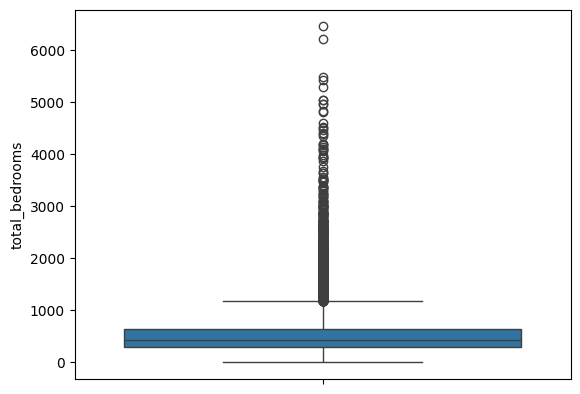

In [23]:
sns.boxplot(df['total_bedrooms'])

In [24]:
df['total_bedrooms']=df['total_bedrooms'].fillna(df['total_bedrooms'].median())

In [25]:
Q1 = df['total_bedrooms'].quantile(0.25)
Q3 = df['total_bedrooms'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
df['total_bedrooms']=df['total_bedrooms'].clip(lower,upper)


<Axes: ylabel='total_bedrooms'>

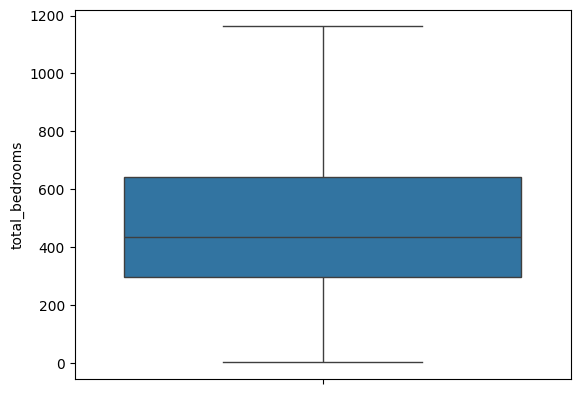

In [26]:
sns.boxplot(df['total_bedrooms'])

In [27]:
df.isnull().sum()

,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [28]:
#Doing one hot encoding for categorical column
df = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True, dtype=int)
df.head()


,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,1,0
1,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,1,0
2,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,1,0
3,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,1,0
4,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,1,0


In [30]:
X=df.drop(columns=['median_house_value'])
y=df['median_house_value']


In [31]:
# Split and scale
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [32]:
# Train and evaluate models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0, max_iter=10000)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    results.append([name, mean_absolute_error(y_test, pred),
                    mse, np.sqrt(mse), r2_score(y_test, pred)])

comparison = pd.DataFrame(results, columns=["Model", "MAE", "MSE", "RMSE", "R2"])
display(comparison.round(4))

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,50863.9518,4.942249e+09,70301.1295,0.6228
1,Ridge,50863.8255,4.942258e+09,70301.1955,0.6228
2,Lasso,50863.9435,4.942261e+09,70301.2184,0.6228


In [33]:
# Compare coefficients
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Linear": models["Linear Regression"].coef_,
    "Ridge": models["Ridge"].coef_,
    "Lasso": models["Lasso"].coef_
})
display(coefficients.round(4))

,Feature,Linear,Ridge,Lasso
0,housing_median_age,16121.4568,16120.5244,16120.7811
1,total_rooms,-6536.3144,-6509.0230,-6518.8777
2,total_bedrooms,14587.0295,14593.9569,14586.6718
3,population,-43510.1675,-43483.8772,-43502.5091
4,households,43129.5210,43071.7333,43105.6026
5,median_income,75616.1224,75606.1983,75611.4489
6,ocean_proximity_INLAND,-31851.3027,-31853.4645,-31853.1973
7,ocean_proximity_ISLAND,2521.0736,2520.8162,2520.0061
8,ocean_proximity_NEAR BAY,739.8488,741.9669,739.3237
9,ocean_proximity_NEAR OCEAN,3974.2349,3974.8739,3973.1970


In [34]:
# Conclusion
best = comparison.loc[comparison["RMSE"].idxmin(), "Model"]
print(f"{best} had the lowest test RMSE, so it performed best on this test set.")
print("Ridge shrinks coefficients, while Lasso can set some coefficients to zero; regularization may help reduce overfitting.")

Linear Regression had the lowest test RMSE, so it performed best on this test set.
Ridge shrinks coefficients, while Lasso can set some coefficients to zero; regularization may help reduce overfitting.
